# Experimento de mejora del accuracy antes del estreno

Se comparan dos representaciones para cada uno de los cuatro modelos: la base del
proyecto y una ampliada con identidades de productoras, actores y directores.
Los datos añadidos ya están en los CSV. No se incorporan votos, popularidad,
recaudaciones como predictores ni información posterior al estreno.

**Evaluación:** tres folds externos, con ajuste en dos folds internos, exclusivamente
en las 2.583 películas del entrenamiento original. El criterio cambia a accuracy,
priorizando candidatos con F1 macro interno de al menos 0.55. Si ninguno lo alcanza, se selecciona el de mayor F1 macro y se informa el incumplimiento.
Cada familia y representación usa los mismos folds y presupuesto de cuatro candidatos.

Las 646 películas de prueba originales se excluyen de este experimento. Su resultado
anterior ya fue observado: no se vuelve a usar esa prueba para buscar mejoras.
Las cifras de CV de este notebook no se comparan directamente con el 66.1% de prueba
del notebook original. La comparación válida es base frente a ampliada bajo este protocolo.

In [1]:
from pathlib import Path
import json, platform, sys, time, hashlib, bisect, importlib.metadata
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
threadpool_controller = threadpool_limits(limits=1)

SEED = 42
THRESHOLD = 2.0
TEST_SIZE = 0.20
N_SPLITS = 3
N_REPEATS = 3
F1_TOLERANCE = 0.01
BASE = Path.cwd()
if BASE.name=='experimentos': BASE=BASE.parent
candidates = [BASE, BASE/'dataset', BASE/'Proyecto-Integrador',
              BASE/'Proyecto-Integrador/dataset', Path('/content')]
DATA_DIR = next((folder for folder in candidates
                 if all((folder/f).exists() for f in ['tmdb_5000_movies.csv','tmdb_5000_credits.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError(f'No se encuentran ambos CSV desde {BASE}. Colocarlos junto al notebook o en dataset/.')
print('Carpeta de datos:', DATA_DIR)
OUT = BASE / 'experimentos/resultados_mejora'
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
environment = {'python': sys.version, 'platform': platform.platform(), 'processor': platform.processor(),
               'versions': {p: importlib.metadata.version(p) for p in ['pandas','numpy','scikit-learn','matplotlib']},
               'seed': SEED, 'cv_folds': N_SPLITS, 'benchmark_repetitions': N_REPEATS,
               'threads': 'Estimadores y búsqueda con n_jobs=1; bibliotecas numéricas limitadas a un hilo con threadpoolctl.'}
display(environment)

Carpeta de datos: C:\Users\Usuario\Documents\UCB-SW\SEM6\MachineLearning\ML-Bloque2\Proyecto-Integrador\Proyecto-Integrador\dataset


{'python': '3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]',
 'platform': 'Windows-11-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel',
 'versions': {'pandas': '3.0.5',
  'numpy': '2.5.2',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1'},
 'seed': 42,
 'cv_folds': 3,
 'benchmark_repetitions': 3,
 'threads': 'Estimadores y búsqueda con n_jobs=1; bibliotecas numéricas limitadas a un hilo con threadpoolctl.'}

## 1. Misma colección, etiqueta y partición original

In [2]:
movies = pd.read_csv(DATA_DIR / 'tmdb_5000_movies.csv')
credits = pd.read_csv(DATA_DIR / 'tmdb_5000_credits.csv')
assert not movies['id'].duplicated().any(), 'IDs duplicados en películas.'
assert not credits['movie_id'].duplicated().any(), 'IDs duplicados en créditos.'
assert set(movies['id']) == set(credits['movie_id']), 'Películas sin créditos o IDs adicionales.'
raw = movies.merge(credits.drop(columns='title'), left_on='id', right_on='movie_id', validate='one_to_one')
quality = pd.DataFrame({'nulos': raw.isna().sum(),
                        'porcentaje_nulos': raw.isna().mean().mul(100).round(2)})
display(quality)
valid = raw['budget'].gt(0) & raw['revenue'].gt(0)
data = raw.loc[valid].copy()
data['release_date'] = pd.to_datetime(data['release_date'], errors='coerce')
data = data.loc[data['release_date'].notna()].copy()
data['runtime'] = data['runtime'].where(data['runtime'].gt(0), np.nan)
data['exito'] = data['revenue'].ge(THRESHOLD * data['budget']).astype(int)
assert data['exito'].nunique() == 2
audit = {'peliculas_originales': len(movies), 'creditos_originales': len(credits),
         'presupuesto_cero': int(movies.budget.eq(0).sum()),
         'recaudacion_cero': int(movies.revenue.eq(0).sum()),
         'filas_utilizables': len(data), 'filas_excluidas': len(raw)-len(data),
         'clases': {str(k): int(v) for k,v in data.exito.value_counts().sort_index().items()},
         'umbral': THRESHOLD, 'fecha_min': str(data.release_date.min().date()),
         'fecha_max': str(data.release_date.max().date())}
environment['sha256'] = {f: hashlib.sha256((DATA_DIR/f).read_bytes()).hexdigest()
    for f in ['tmdb_5000_movies.csv','tmdb_5000_credits.csv']}
display(audit)
quality.to_csv(OUT/'calidad_datos.csv', index_label='variable')

,nulos,porcentaje_nulos
budget,0,0.00
genres,0,0.00
homepage,3091,64.36
id,0,0.00
keywords,0,0.00
original_language,0,0.00
original_title,0,0.00
overview,3,0.06
popularity,0,0.00
production_companies,0,0.00


{'peliculas_originales': 4803,
 'creditos_originales': 4803,
 'presupuesto_cero': 1037,
 'recaudacion_cero': 1427,
 'filas_utilizables': 3229,
 'filas_excluidas': 1574,
 'clases': {'0': 1420, '1': 1809},
 'umbral': 2.0,
 'fecha_min': '1916-09-04',
 'fecha_max': '2016-09-09'}

In [3]:
def parse_list(value):
    return json.loads(value) if isinstance(value, str) else []

X = pd.DataFrame(index=data.index)
X['budget'] = data.budget
X['runtime'] = data.runtime
X['release_date'] = data.release_date
X['release_year'] = data.release_date.dt.year
X['release_month'] = data.release_date.dt.month.astype(str)
X['original_language'] = data.original_language.fillna('desconocido')
X['country'] = data.production_countries.map(lambda s: (parse_list(s)[0]['iso_3166_1']
    if parse_list(s) else 'desconocido'))
X['genre_tokens'] = data.genres.map(lambda s: ' '.join('g'+str(g['id']) for g in parse_list(s)))
X['cast_ids'] = data.cast.map(lambda s: tuple(int(a['id']) for a in parse_list(s)[:5]))
X['director_ids'] = data.crew.map(lambda s: tuple(int(a['id']) for a in parse_list(s) if a['job']=='Director'))
y = data.exito
assert not {'revenue','popularity','vote_average','vote_count','exito'}.intersection(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE,
                                                stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
split_manifest = pd.DataFrame({'id': data.id, 'conjunto': np.where(data.index.isin(X_train.index),
                                                               'entrenamiento','prueba')})
split_manifest.to_csv(OUT/'particion.csv', index=False)
display(pd.DataFrame({'entrenamiento': y_train.value_counts().sort_index(),
                      'prueba': y_test.value_counts().sort_index()}))

,entrenamiento,prueba
exito,,
0,1136,284
1,1447,362


## 2. Representaciones comparables
Base: presupuesto, duración, fecha, idioma, país, géneros y trayectoria observada.
Ampliada: incorpora presencia de productoras y personas por identificadores.
Solo se conservan identificadores suficientemente frecuentes en cada entrenamiento.
Su vocabulario se aprende dentro de cada fold; los desconocidos quedan sin activar.
Estas identidades se suponen conocidas durante la planificación de la película.

In [4]:
class HistoricalFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.histories_ = {'cast_ids': defaultdict(list), 'director_ids': defaultdict(list)}
        for field, histories in self.histories_.items():
            for ids, date in zip(X[field], X.release_date):
                for person in set(ids):
                    histories[person].append(pd.Timestamp(date).value)
            for dates in histories.values():
                dates.sort()
        return self

    def transform(self, X):
        frame = X.copy()
        frame['log_budget'] = np.log1p(frame.budget)
        for field, output in [('cast_ids','cast_experience'),('director_ids','director_experience')]:
            histories = self.histories_[field]
            frame[output] = [np.log1p(np.mean([bisect.bisect_left(histories.get(p, []),
                            pd.Timestamp(date).value) for p in set(ids)])) if ids else 0.0
                for ids, date in zip(X[field], X.release_date)]
        return frame

numeric = ['log_budget','runtime','release_year','cast_experience','director_experience']
categorical = ['release_month','original_language','country']
def make_pipeline(model, scale=False):
    steps = [('imputer',SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale',StandardScaler()))
    preprocess = ColumnTransformer([
        ('numeric',Pipeline(steps),numeric),
        ('categorical',OneHotEncoder(handle_unknown='ignore',min_frequency=20,sparse_output=False),categorical),
        ('genres',CountVectorizer(binary=True,token_pattern=r'g\d+'), 'genre_tokens')
    ], sparse_threshold=0,verbose_feature_names_out=True)
    return Pipeline([('history',HistoricalFeatures()),('preprocess',preprocess),('model',model)])

In [5]:
X_extended=X.copy()
X_extended['company_tokens']=data.production_companies.map(
    lambda value:' '.join('p'+str(company['id']) for company in parse_list(value)))
X_extended['actor_tokens']=X.cast_ids.map(lambda ids:' '.join('a'+str(person) for person in ids))
X_extended['director_tokens']=X.director_ids.map(lambda ids:' '.join('d'+str(person) for person in ids))
X_dev=X_extended.loc[X_train.index].copy()
y_dev=y_train.copy()
assert not set(X_dev.index)&set(X_test.index)
assert len(X_dev)==len(y_dev)
del X_test,y_test  # Este experimento no evalúa la prueba anterior.

def pipeline_variant(model,scale,extended):
    if not extended:
        return make_pipeline(model,scale=scale)
    numeric_steps=[('impute',SimpleImputer(strategy='median'))]
    if scale:numeric_steps.append(('scale',StandardScaler()))
    transforms=[
        ('numeric',Pipeline(numeric_steps),numeric),
        ('categorical',OneHotEncoder(handle_unknown='ignore',min_frequency=20,sparse_output=False),categorical),
        ('genres',CountVectorizer(binary=True,token_pattern=r'g\d+'),'genre_tokens'),
        ('companies',CountVectorizer(binary=True,token_pattern=r'p\d+',min_df=5,max_features=200),'company_tokens'),
        ('actors',CountVectorizer(binary=True,token_pattern=r'a\d+',min_df=5,max_features=300),'actor_tokens'),
        ('directors',CountVectorizer(binary=True,token_pattern=r'd\d+',min_df=3,max_features=150),'director_tokens')]
    return Pipeline([('history',HistoricalFeatures()),
        ('preprocess',ColumnTransformer(transforms,sparse_threshold=0)),('model',model)])

specs={
    'SVM':(SVC(kernel='rbf'),True,{'model__C':[1,3],'model__gamma':['scale',.003]}),
    'Arbol':(DecisionTreeClassifier(random_state=SEED),False,
             {'model__max_depth':[6,None],'model__min_samples_leaf':[10,30]}),
    'RandomForest':(RandomForestClassifier(n_estimators=150,max_features=.5,random_state=SEED,n_jobs=1),False,
                    {'model__max_depth':[12,None],'model__min_samples_leaf':[5,15]}),
    'Boosting':(GradientBoostingClassifier(n_estimators=200,min_samples_leaf=10,
                n_iter_no_change=15,validation_fraction=.2,tol=.001,random_state=SEED),False,
                {'model__learning_rate':[.03,.1],'model__max_depth':[2,3]})}

def choose_candidate(results):
    accuracy=np.asarray(results['mean_test_accuracy'])
    macro=np.asarray(results['mean_test_f1_macro'])
    candidates=np.flatnonzero(macro>=.55)
    return int(candidates[np.argmax(accuracy[candidates])]) if len(candidates) else int(np.argmax(macro))

outer=StratifiedKFold(n_splits=3,shuffle=True,random_state=20261017)
outer_splits=list(outer.split(X_dev,y_dev))
experiment_rows=[]
oof=pd.DataFrame({'id':data.loc[X_dev.index,'id'],'real':y_dev},index=X_dev.index)

def evaluate_outer(fold):
    train_pos,val_pos=outer_splits[fold]
    xx, xv=X_dev.iloc[train_pos],X_dev.iloc[val_pos]
    yy, yv=y_dev.iloc[train_pos],y_dev.iloc[val_pos]
    inner=StratifiedKFold(n_splits=2,shuffle=True,random_state=20261020+fold)
    for name,(estimator,scale,grid) in specs.items():
        for representation,extended in [('base',False),('ampliada',True)]:
            search=GridSearchCV(pipeline_variant(clone(estimator),scale,extended),grid,
                scoring={'accuracy':'accuracy','f1_macro':'f1_macro','roc_auc':'roc_auc'},
                cv=inner,refit=choose_candidate,n_jobs=1,error_score='raise')
            start=time.perf_counter();search.fit(xx,yy)
            elapsed=time.perf_counter()-start
            prediction=search.predict(xv)
            score=(search.decision_function(xv) if hasattr(search,'decision_function')
                   else search.predict_proba(xv)[:,1])
            row={'modelo':name,'representacion':representation,'fold':fold+1,
                 'accuracy':accuracy_score(yv,prediction),
                 'f1_macro':f1_score(yv,prediction,average='macro'),
                 'roc_auc':roc_auc_score(yv,score),'busqueda_refit_s':elapsed,
                 'mejores_parametros':json.dumps(search.best_params_),
                 'f1_macro_interno':float(search.cv_results_['mean_test_f1_macro'][search.best_index_])}
            experiment_rows.append(row)
            oof.loc[xv.index,name+'_'+representation]=prediction
            print(f'Fold {fold+1} {name} {representation}: accuracy={row["accuracy"]:.3f}, F1 macro={row["f1_macro"]:.3f}',flush=True)
            pd.DataFrame(experiment_rows).to_csv(OUT/'validacion_anidada_particiones.csv',index=False)
            oof.to_csv(OUT/'predicciones_oof.csv',index=False)

## 3. Evaluación externa de la partición 1

In [6]:
evaluate_outer(0)

Fold 1 SVM base: accuracy=0.636, F1 macro=0.620
Fold 1 SVM ampliada: accuracy=0.649, F1 macro=0.645
Fold 1 Arbol base: accuracy=0.587, F1 macro=0.583
Fold 1 Arbol ampliada: accuracy=0.580, F1 macro=0.573
Fold 1 RandomForest base: accuracy=0.628, F1 macro=0.606
Fold 1 RandomForest ampliada: accuracy=0.643, F1 macro=0.633
Fold 1 Boosting base: accuracy=0.603, F1 macro=0.588
Fold 1 Boosting ampliada: accuracy=0.633, F1 macro=0.618


## 4. Evaluación externa de la partición 2

In [7]:
evaluate_outer(1)

Fold 2 SVM base: accuracy=0.590, F1 macro=0.574
Fold 2 SVM ampliada: accuracy=0.628, F1 macro=0.621
Fold 2 Arbol base: accuracy=0.540, F1 macro=0.538
Fold 2 Arbol ampliada: accuracy=0.542, F1 macro=0.540
Fold 2 RandomForest base: accuracy=0.581, F1 macro=0.569
Fold 2 RandomForest ampliada: accuracy=0.585, F1 macro=0.576
Fold 2 Boosting base: accuracy=0.562, F1 macro=0.545
Fold 2 Boosting ampliada: accuracy=0.583, F1 macro=0.572


## 5. Evaluación externa de la partición 3

In [8]:
evaluate_outer(2)

Fold 3 SVM base: accuracy=0.612, F1 macro=0.595
Fold 3 SVM ampliada: accuracy=0.621, F1 macro=0.612
Fold 3 Arbol base: accuracy=0.609, F1 macro=0.602
Fold 3 Arbol ampliada: accuracy=0.584, F1 macro=0.574
Fold 3 RandomForest base: accuracy=0.633, F1 macro=0.621
Fold 3 RandomForest ampliada: accuracy=0.630, F1 macro=0.618
Fold 3 Boosting base: accuracy=0.606, F1 macro=0.591
Fold 3 Boosting ampliada: accuracy=0.619, F1 macro=0.603


## 6. Comparación de mejoras
Las diferencias se calculan sobre los mismos folds externos. Tres folds ofrecen una
evaluación preliminar, no una garantía de que la mejora se repita en otros periodos.
Una estrategia no mejora solo por ser más compleja. Se muestran también los modelos
que empeoran. El notebook e informe originales conservan su evaluación previa.

,modelo,representacion,accuracy_media,accuracy_desv,f1_macro_media,roc_auc_media,busqueda_total_s
0,Arbol,ampliada,0.5687,0.0229,0.5625,0.6005,16.9130
1,Arbol,base,0.5784,0.0350,0.5743,0.5977,13.8945
2,Boosting,ampliada,0.6117,0.0258,0.5974,0.6495,38.1303
3,Boosting,base,0.5904,0.0245,0.5746,0.6366,18.8240
4,RandomForest,ampliada,0.6194,0.0303,0.6089,0.6611,78.6787
5,RandomForest,base,0.6140,0.0289,0.5984,0.6549,41.7221
6,SVM,ampliada,0.6330,0.0145,0.6256,0.6786,58.5620
7,SVM,base,0.6129,0.0232,0.5963,0.6497,20.8072


representacion     ampliada    base  mejora_pp
modelo       fold                             
Arbol        1       0.5796  0.5865    -0.6969
             2       0.5424  0.5401     0.2323
             3       0.5842  0.6086    -2.4390
Boosting     1       0.6330  0.6028     3.0197
             2       0.5830  0.5621     2.0906
             3       0.6190  0.6063     1.2776
RandomForest 1       0.6434  0.6283     1.5099
             2       0.5854  0.5807     0.4646
             3       0.6295  0.6330    -0.3484
SVM          1       0.6492  0.6365     1.2776
             2       0.6283  0.5900     3.8328
             3       0.6214  0.6121     0.9292

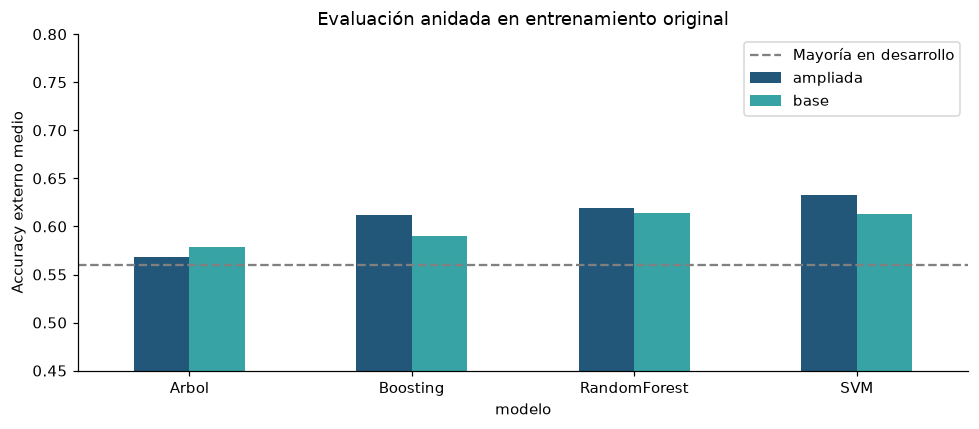

**Mejor estrategia observada en esta evaluación:** SVM, representación ampliada, accuracy medio 63.3%. Este resultado pertenece a validación anidada sobre desarrollo. Para afirmar mejora en generalización final hacen falta observaciones adicionales no utilizadas en estas decisiones.

In [9]:
experiment=pd.DataFrame(experiment_rows)
assert len(experiment)==24
assert not oof.drop(columns=['id','real']).isna().any().any()
result=experiment.groupby(['modelo','representacion']).agg(
    accuracy_media=('accuracy','mean'),accuracy_desv=('accuracy','std'),
    f1_macro_media=('f1_macro','mean'),roc_auc_media=('roc_auc','mean'),
    busqueda_total_s=('busqueda_refit_s','sum')).reset_index()
result.to_csv(OUT/'comparacion_validacion_anidada.csv',index=False)
paired=experiment.pivot(index=['modelo','fold'],columns='representacion',values='accuracy')
paired['mejora_pp']=(paired['ampliada']-paired['base'])*100
paired.to_csv(OUT/'mejoras_pareadas.csv')
display(result.round(4));display(paired.round(4))
fig,ax=plt.subplots(figsize=(9,4))
result.pivot(index='modelo',columns='representacion',values='accuracy_media').plot.bar(ax=ax,color=['#22577a','#38a3a5'])
ax.axhline(y_dev.value_counts(normalize=True).max(),color='gray',linestyle='--',label='Mayoría en desarrollo')
ax.set(ylabel='Accuracy externo medio',title='Evaluación anidada en entrenamiento original',ylim=(.45,.8))
ax.legend();ax.tick_params(axis='x',rotation=0);fig.tight_layout()
fig.savefig(OUT/'comparacion_accuracy.png',dpi=180);plt.show()
best_index=result.accuracy_media.idxmax();winner=result.loc[best_index]
model_name=winner.modelo
same_model=result.loc[(result.modelo==model_name)&(result.representacion=='base')].iloc[0]
report={'protocolo':'CV anidada 3 externa x 2 interna en desarrollo original; accuracy con restricción interna F1 macro >= .55',
    'n_desarrollo':len(X_dev),'n_prueba_original_excluida':646,
    'variables_nuevas':['productoras','identidades del elenco','identidades de directores'],
    'comparacion':result.to_dict('records'),'mejora_pareada_pp':paired.reset_index().to_dict('records'),
    'mejor_estrategia_observada':winner.to_dict(),
    'nota':'Resultados de desarrollo; no son una nueva prueba independiente ni se comparan directamente con accuracy de prueba anterior.'}
(OUT/'resumen_mejora.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
display(Markdown(f'**Mejor estrategia observada en esta evaluación:** {winner.modelo}, '
    f'representación {winner.representacion}, accuracy medio {winner.accuracy_media:.1%}. '
    'Este resultado pertenece a validación anidada sobre desarrollo. '
    'Para afirmar mejora en generalización final hacen falta observaciones adicionales no utilizadas en estas decisiones.'))

## 6.1. Ajuste del modelo candidato
Se ajusta la estrategia observada con mayor accuracy externo en todo el desarrollo. No se reutiliza la prueba anterior para medirla.

In [10]:
# Ajuste final en desarrollo: no se vuelve a evaluar la prueba original.
report=json.loads((OUT/'resumen_mejora.json').read_text(encoding='utf-8'))
choice=report['mejor_estrategia_observada']
name=choice['modelo']
extended=choice['representacion']=='ampliada'
estimator,scale,grid=specs[name]
final_search=GridSearchCV(pipeline_variant(clone(estimator),scale,extended),grid,
    scoring={'accuracy':'accuracy','f1_macro':'f1_macro','roc_auc':'roc_auc'},
    cv=StratifiedKFold(n_splits=2,shuffle=True,random_state=20261029),
    refit=choose_candidate,n_jobs=1,error_score='raise')
final_search.fit(X_dev,y_dev)
modelo_mejorado=final_search.best_estimator_
manifest={'modelo':name,'representacion':choice['representacion'],
    'parametros':final_search.best_params_, 'peliculas_entrenamiento':len(X_dev),
    'dimensiones_transformadas':int(modelo_mejorado.named_steps['model'].n_features_in_),
    'accuracy_cv_anidada_observada':choice['accuracy_media'],
    'nota':'Modelo ajustado en desarrollo. Falta evaluación adicional independiente para confirmar generalización final.'}
(OUT/'modelo_candidato.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Modelo candidato entrenado:',name,choice['representacion'])
print('Parámetros:',final_search.best_params_)
print('No se calculan métricas sobre las 646 películas de prueba anteriores.')
display(modelo_mejorado)


Modelo candidato entrenado: SVM ampliada
Parámetros: {'model__C': 1, 'model__gamma': 'scale'}
No se calculan métricas sobre las 646 películas de prueba anteriores.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('history', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
Name,Type,Value
histories_,dict,"{'ca...ds': defaultdict(<...00000000000]}), 'di...ds': defaultdict(<...00000000000]})}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder=

## 7. Datos nuevos que podrían aportar información
Priorizar registros enlazables mediante ID de TMDb y con fechas y fuentes verificables:
presupuesto/recaudación con unidades consistentes; pertenencia a franquicia o secuela;
clasificación por edades; marketing; trayectoria del elenco y directores anterior a
cada estreno; y señales promocionales registradas antes de la fecha de predicción.

Para una predicción a siete días del estreno se necesitarían cifras de esa primera
semana, salas y recepción medida hasta ese día. Los votos actuales sin fecha de
captura no permiten reconstruir ese escenario. No se garantiza un accuracy objetivo.

Documentación de CV anidada:
https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html